# Matterport Mask R-CNN

Train Matterport Mask R-CNN on [JuniperMapper dataset](https://zenodo.org/records/10058715) dataset.

Use three independent subsets inside the Photo Interpretation Data:

| Subset     | Purpose                                 |                  Suggested size |
| ---------- | --------------------------------------- | ------------------------------: |
| Training   | Weight optimization                     |                      570 images |
| Validation | Hyperparameter and checkpoint selection |                       67 images |
| Test       | Final unbiased assessment               |      Separate 75-image test set |

## Manageable experimental design

A full grid would be expensive and would increase the probability of selecting a configuration that performs well only by chance. A sequential design is more appropriate. This requires approximately 11–12 initial runs rather than dozens or hundreds.

The best training strategy is selected using validation mask mAP.

### Phase A: training method

Hold architecture constant:

| Experiment | Fine-tuning | Augmentation            |
| ---------- | ----------- | ----------------------- |
| A1         | Heads only  | None                    |
| A2         | Staged      | None                    |
| A3         | Staged      | Geometric               |


The staged schedule steps are:

| Stage | Actual epochs | Number of epochs |
| ----- | ------------: | ---------------: |
| Heads |          1–10 |               10 |
| 4+    |         11–25 |               15 |
| All   |         26–40 |               15 |

These models are trained with a learning rate of 0.001 and ResNet-101 backbone.

### Phase B: learning rate

Using the best Phase A configuration:

| Experiment | Initial LR |
| ---------- | ---------: |
| B1         |     0.0005 |
| B2         |     0.0025 |

### Phase C: backbone

Using the best Phase A + Phase B configuration.

| Experiment | Backbone   |
| ---------- | ---------- |
| C1         | ResNet-50  |

In [1]:
from pathlib import Path
import os
import sys
import math
import json

from imgaug import augmenters as iaa
import numpy as np

sys.path.append(os.path.join(os.path.dirname(os.getcwd()), 'bin'))
from mrcnn import utils
from mrcnn import visualize
from shrubs_matterport import (
    BaselineShrubConfig,
    ShrubDataset,
    TrainingExperiment,
    select_best_experiment,
    scale_training_schedule
)

Using TensorFlow backend.


## Configurations

In [2]:
%matplotlib inline 

ROOT = os.path.join(os.path.dirname(os.getcwd()))

# Directory to save logs and trained model
MODEL_DIR = os.path.join(ROOT, "data/logs")

SCREENING_SEED = 20260803

In [ ]:
EXPERIMENT_ROOT = Path(MODEL_DIR, "matterport")
EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)

In [ ]:
# Directory with train data
TRAIN_DIR = os.path.join(
    ROOT,
    "data/JuniperMapper", "Photo_Interpretation_Data"
)

# Local path to store the COCO trained weights
COCO_MODEL_PATH = os.path.join(ROOT, "data/logs/matterport/mask_rcnn_coco.h5")
# Download COCO trained weights from Releases if needed
if not os.path.exists(COCO_MODEL_PATH):
    utils.download_trained_weights(COCO_MODEL_PATH)

In [5]:
config = BaselineShrubConfig()
config.display()


Configurations:
BACKBONE                       resnet101
BACKBONE_STRIDES               [4, 8, 16, 32, 64]
BATCH_SIZE                     4
BBOX_STD_DEV                   [0.1 0.1 0.2 0.2]
COMPUTE_BACKBONE_SHAPE         None
DETECTION_MAX_INSTANCES        100
DETECTION_MIN_CONFIDENCE       0.7
DETECTION_NMS_THRESHOLD        0.3
FPN_CLASSIF_FC_LAYERS_SIZE     1024
GPU_COUNT                      1
GRADIENT_CLIP_NORM             5.0
IMAGES_PER_GPU                 4
IMAGE_CHANNEL_COUNT            3
IMAGE_MAX_DIM                  448
IMAGE_META_SIZE                14
IMAGE_MIN_DIM                  448
IMAGE_MIN_SCALE                0
IMAGE_RESIZE_MODE              square
IMAGE_SHAPE                    [448 448   3]
LEARNING_MOMENTUM              0.9
LEARNING_RATE                  0.001
LOSS_WEIGHTS                   {'rpn_class_loss': 1.0, 'rpn_bbox_loss': 1.0, 'mrcnn_class_loss': 1.0, 'mrcnn_bbox_loss': 1.0, 'mrcnn_mask_loss': 1.0}
MASK_POOL_SIZE                 14
MASK_SHAPE             

In [6]:
def configure_dataset_steps(config, dataset_train, dataset_val):
    """Helper to define the new configuration between the tests."""
    config.STEPS_PER_EPOCH = math.ceil(
        len(dataset_train.image_ids) / config.BATCH_SIZE
    )
    config.VALIDATION_STEPS = math.ceil(
        len(dataset_val.image_ids) / config.BATCH_SIZE
    )
    return config

## Dataset

In [8]:
DATASET_ID = "JunipperMapper_train_val_partition"

# Training dataset
dataset_train = ShrubDataset()
dataset_train.load_dataset(
    os.path.join(TRAIN_DIR, "Train", "Images"),
    os.path.join(TRAIN_DIR, "Train", "masks_points.json")
)
dataset_train.prepare()

# Validation dataset
dataset_val = ShrubDataset()
dataset_val.load_dataset(
    os.path.join(TRAIN_DIR, "Val", "Images"),
    os.path.join(TRAIN_DIR, "Val", "masks_points.json")
)
dataset_val.prepare()

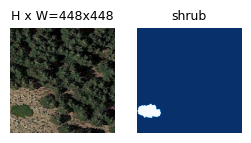

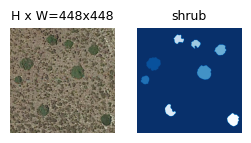

In [9]:
# Load and display random samples
image_ids = np.random.choice(dataset_train.image_ids, 2)
for image_id in image_ids:
    image = dataset_train.load_image(image_id)
    mask, class_ids = dataset_train.load_mask(image_id)
    visualize.display_top_masks(
        image,
        mask,
        class_ids,
        dataset_train.class_names,
        limit=1,
        figsize=(3,3)
    )

## Update training parameters

Update the number of validation batches, not equatl to the number of validation images. Note that this approach has one caveat. The generator yields only when it has accumulated a complete batch. It does not normally produce a smaller final batch. For example, with 67 images and batch size 2, the 34th batch can contain one repeated image from the next dataset cycle.

Consequently, the following line processes 68 image samples, with one validation image potentially appearing twice. We have assumed that.

In [10]:
# Set the number of validation batches
config.VALIDATION_STEPS = math.ceil(
    len(dataset_val.image_ids) / config.BATCH_SIZE
)

The original `STEPS_PER_EPOCH=100` does not cover one complete dataset pass. With a batch size of 2: 100 steps x 2 images = 200 image samples per epoch.

With 570 training images, one nominal epoch processes only approximately 35% of the dataset. Define this value using the available number of images.

In [11]:
config.STEPS_PER_EPOCH = math.ceil(
    len(dataset_train.image_ids) / config.BATCH_SIZE
)

## Inference configuration

Create an inference configuration. Use the same architectural parameters as training, but set one image per batch and retain low-confidence predictions.

The safest pattern is to inherit directly from the same configuration class.


In [12]:
class ShrubInferenceConfig(BaselineShrubConfig):
    GPU_COUNT = 1
    IMAGES_PER_GPU = 1

    # Retain predictions for later threshold selection.
    DETECTION_MIN_CONFIDENCE = 0.0
    DETECTION_MAX_INSTANCES = 256

inference_config = ShrubInferenceConfig()

## Augmentation

Horizontal and vertical flips and right-angle rotations. Arbitrary rotations can interpolate mask boundaries. A cleaner initial experiment uses only 90° rotations.

For this tests, conducted in nadir aerial imagery, shrub orientation normally has no semantic meaning.

Avoid aggressive transformations unless they represent realistic variability in your imagery. In particular:

- avoid vertical perspective distortion for orthorectified imagery;
- avoid strong hue changes if shrub colour is biologically meaningful;
- avoid blur unless acquisition blur occurs in the real data;
- avoid large scaling if shrub pixel size is relatively consistent;
- do not augment validation or test images.

In [13]:
augmentation_meta = {
    "metadata": {
        "name": "geometric",
        "horizontal_flip_probability": 0.5,
        "vertical_flip_probability": 0.5,
        "rotation_probability": 0.75,
        "rotation_quarter_turns": [1, 2, 3]
    },
    "obj": iaa.Sequential(
        [
            # Horizontal flip
            iaa.Fliplr(0.5),
            # Vertical flip
            iaa.Flipud(0.5),
            # Rotation_90_degrees
            iaa.Sometimes(
                0.75,
                iaa.Rot90((1, 3)),
            ),
        ],
        random_order=True
    )
}

## Training

In Matterport, the epochs argument is cumulative. Thus, the following stages train:

- epochs 1–10: heads;
- epochs 11–25: stage 4 and above;
- epochs 26–40: all layers.

**Important: Do not reinitialize the model between stages.**

### Experiment A1

Train only the heads of the model.

In [14]:
training_stages_a1 = [
    {
        "name": "heads",
        "layers": "heads",
        "initial_epoch": 0,
        "final_epoch": 10,
        "learning_rate": 1e-3,
    }
]

In [ ]:
experiment_a1 = TrainingExperiment(
    name="baseline_heads_noaug",
    config=config,
    inference_config=inference_config,
    dataset_train=dataset_train,
    dataset_val=dataset_val,
    experiment_root=EXPERIMENT_ROOT,
    coco_model_path=COCO_MODEL_PATH,
    stages=training_stages_a1,
    dataset_partition=DATASET_ID,
    seed=SCREENING_SEED,
    augmentation=None,
    augmentation_metadata={"name": "none"},
)

results_a1 = experiment_a1.run()

In [ ]:
experiment_a1_resume = TrainingExperiment(
    name="baseline_heads_noaug",
    config=config,
    inference_config=inference_config,
    dataset_train=None,
    dataset_val=dataset_val,
    experiment_root=EXPERIMENT_ROOT,
    coco_model_path=COCO_MODEL_PATH,
    stages=training_stages_a1,
    seed=SCREENING_SEED,
    dataset_partition=DATASET_ID,
    augmentation=None,
    augmentation_metadata={"name": "none"},
    execution_mode="evaluation_only",
    prior_run_directory=(
        EXPERIMENT_ROOT /
        "baseline_heads_noaug_seed20260803_20260804T182415"
    ),
)

results_a1 = experiment_a1_resume.run()

### Experiment A2

Staged training without augmentation. Use the same model object for all three calls.

In [14]:
training_stages_a2 = [
    {
        "name": "heads",
        "layers": "heads",
        "initial_epoch": 0,
        "final_epoch": 10,
        "learning_rate": 1e-3,
    },
    {
        "name": "resnet_stage_4_and_above",
        "layers": "4+",
        "initial_epoch": 10,
        "final_epoch": 25,
        "learning_rate": 5e-4,
    },
    {
        "name": "all_layers",
        "layers": "all",
        "initial_epoch": 25,
        "final_epoch": 40,
        "learning_rate": 1e-4,
    },
]

In [ ]:
experiment_a2 = TrainingExperiment(
    name="baseline_staged_noaug",
    config=config,
    inference_config=inference_config,
    dataset_train=dataset_train,
    dataset_val=dataset_val,
    experiment_root=EXPERIMENT_ROOT,
    coco_model_path=COCO_MODEL_PATH,
    stages=training_stages_a2,
    dataset_partition=DATASET_ID,
    seed=SCREENING_SEED,
    augmentation=None,
    augmentation_metadata={"name": "none"},
    execution_mode="full",
)

results_a2 = experiment_a2.run()

### Experiment A3

In [ ]:
experiment_a3 = TrainingExperiment(
    name="baseline_staged_aug_geometric",
    config=config,
    inference_config=inference_config,
    dataset_train=dataset_train,
    dataset_val=dataset_val,
    experiment_root=EXPERIMENT_ROOT,
    coco_model_path=COCO_MODEL_PATH,
    stages=training_stages_a2,
    dataset_partition=DATASET_ID,
    seed=SCREENING_SEED,
    augmentation=augmentation_meta["obj"],
    augmentation_metadata=augmentation_meta["metadata"],
    execution_mode="full",
)

results_a3 = experiment_a3.run()

### Best phase 1 experiment

In [15]:
# Select the best model from the prior three tests
PHASE_1_NAMES = {
    "baseline_heads_noaug",
    "baseline_staged_noaug",
    "baseline_staged_aug_geometric",
}

best_phase1 = select_best_experiment(
    EXPERIMENT_ROOT,
    experiment_names=PHASE_1_NAMES,
)

print("Best Phase 1 experiment:")
print(best_phase1["experiment_name"])
print(
    best_phase1["validation_metrics"]["mask_mAP_50_95"]
)

Best Phase 1 experiment:
baseline_staged_noaug
0.5770367992464955


In [14]:
best_stages = best_phase1["training_schedule"]
best_augmentation_name = (
    best_phase1["augmentation_metadata"]["name"]
)
best_configuration = best_phase1["configuration"]

In [15]:
AUGMENTATIONS = {
    "none": None,
    "geometric": augmentation_meta["obj"],
}

best_augmentation = AUGMENTATIONS[
    best_augmentation_name
]

### Experiment B1

Second phase of the experiments. Select the best model from the above three tests and check the learning ration.

In [16]:
class Phase2LR0005Config(BaselineShrubConfig):
    LEARNING_RATE = 5e-4


config_b1 = configure_dataset_steps(
    Phase2LR0005Config(),
    dataset_train,
    dataset_val,
)

stages_b1 = scale_training_schedule(best_stages, 5e-4)

In [ ]:
experiment_b1 = TrainingExperiment(
    name="phase2_lr_0005",
    config=config_b1,
    inference_config=inference_config,
    dataset_train=dataset_train,
    dataset_val=dataset_val,
    experiment_root=EXPERIMENT_ROOT,
    coco_model_path=COCO_MODEL_PATH,
    stages=stages_b1,
    seed=SCREENING_SEED,
    dataset_partition=DATASET_ID,
    augmentation=best_augmentation,
    augmentation_metadata=best_phase1[
        "augmentation_metadata"
    ],
)

results_b1 = experiment_b1.run()

### Experiment B2

In [ ]:
class Phase2LR0025Config(BaselineShrubConfig):
    LEARNING_RATE = 0.0025


config_b2 = configure_dataset_steps(
    Phase2LR0025Config(),
    dataset_train,
    dataset_val,
)

stages_b2 = scale_training_schedule(best_stages, 0.0025)

In [ ]:
experiment_b2 = TrainingExperiment(
    name="phase2_lr_0025",
    config=config_b2,
    inference_config=inference_config,
    dataset_train=dataset_train,
    dataset_val=dataset_val,
    experiment_root=EXPERIMENT_ROOT,
    coco_model_path=COCO_MODEL_PATH,
    stages=stages_b2,
    seed=SCREENING_SEED,
    dataset_partition=DATASET_ID,
    augmentation=best_augmentation,
    augmentation_metadata=best_phase1[
        "augmentation_metadata"
    ],
)

results_b2 = experiment_b2.run()

### Best Phase 1 + 2 experiments

In [16]:
# Select the best model from the prior three tests
PHASE_2_NAMES = {
    best_phase1["experiment_name"],
    "phase2_lr_0005",
    "phase2_lr_0025",
}

best_phase2 = select_best_experiment(
    EXPERIMENT_ROOT,
    experiment_names=PHASE_2_NAMES,
)

print("Best Phase 1 + 2 experiment:")
print(best_phase2["experiment_name"])
print(
    best_phase2["validation_metrics"]["mask_mAP_50_95"]
)

Best Phase 1 + 2 experiment:
phase2_lr_0025
0.6101513148816566


In [21]:
best_phase2_stages = best_phase2["training_schedule"]
best_phase2_augmentation_name = (
    best_phase2["augmentation_metadata"]["name"]
)

best_configuration2 = best_phase2["configuration"]

In [19]:
AUGMENTATIONS = {
    "none": None,
    "geometric": augmentation_meta["obj"],
}

best_phase2_augmentation = AUGMENTATIONS[
    best_phase2_augmentation_name
]

### Experiment C1

In [28]:
class Phase3Config(BaselineShrubConfig):
    LEARNING_RATE = best_configuration2["LEARNING_RATE"]
    BACKBONE = "resnet50"

class Phase3InferenceConfig(ShrubInferenceConfig):
    BACKBONE = "resnet50"

config_c1 = configure_dataset_steps(
    Phase3Config(),
    dataset_train,
    dataset_val,
)

inference_config_c1 = Phase3InferenceConfig()

# Get the best learning rate
stages_c1 = scale_training_schedule(best_phase2_stages, 0.0025)

In [ ]:
experiment_c1 = TrainingExperiment(
    name="phase3_resnet50",
    config=config_c1,
    inference_config=inference_config_c1,
    dataset_train=dataset_train,
    dataset_val=dataset_val,
    experiment_root=EXPERIMENT_ROOT,
    coco_model_path=COCO_MODEL_PATH,
    stages=stages_c1,
    seed=SCREENING_SEED,
    dataset_partition=DATASET_ID,
    augmentation=best_phase2_augmentation,
    augmentation_metadata=best_phase2[
        "augmentation_metadata"
    ],
)

results_c1 = experiment_c1.run()

## Best model configurations

Compare the Phase B winner, representing the ResNet-101 candidate; and Phase3 test, representing the ResNet-50 candidate.

In [ ]:
PHASE_3_NAMES = {
    best_phase2["experiment_name"],
    "phase3_resnet50",
}

best_final = select_best_experiment(
    EXPERIMENT_ROOT,
    experiment_names=PHASE_3_NAMES,
)

metrics = best_final["validation_metrics"]

print("Best final experiment")
print("---------------------")
print("Experiment:", best_final["experiment_name"])
print("Backbone:", best_final["configuration"]["BACKBONE"])
print(
    "Base learning rate:",
    best_final["configuration"]["LEARNING_RATE"],
)
print(
    "Augmentation:",
    best_final["augmentation_metadata"]["name"],
)
print(
    "Best epoch:",
    best_final["best_checkpoint_epoch"],
)
print(
    "Mask mAP50–95:",
    metrics["mask_mAP_50_95"],
)
print("Mask AP50:", metrics["mask_AP50"])
print("Mask AP75:", metrics["mask_AP75"])
print(
    "Confidence threshold:",
    metrics["selected_confidence_threshold"],
)
print("F1:", metrics["f1"])
print("Best weights:", best_final["best_checkpoint_path"])

In [31]:
final_model_configuration = {
    "experiment_name": best_final["experiment_name"],
    "configuration": best_final["configuration"],
    "best_learning_rate": best_final[
        "training_schedule"
    ][0]["learning_rate"],
    "training_schedule": best_final["training_schedule"],
    "augmentation": best_final["augmentation_metadata"],
    "random_seed": best_final["random_seed"],
    "dataset_partition": best_final["dataset_partition"],
    "best_checkpoint_epoch": best_final[
        "best_checkpoint_epoch"
    ],
    "best_checkpoint_path": best_final[
        "best_checkpoint_path"
    ],
    "validation_metrics": best_final[
        "validation_metrics"
    ],
}

In [ ]:
final_configuration_path = (
    EXPERIMENT_ROOT / "best_model_configuration.json"
)

with final_configuration_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        final_model_configuration,
        file,
        indent=2,
        ensure_ascii=False,
    )

print("Saved to:", final_configuration_path)